<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula-01/MBA_DL_Aula_1_01_demo_conceito_gradiente_backprop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1 | Demo de conceito: como uma rede aprende a partir do erro

**MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio**

Este notebook tem uma ideia por célula. A professora roda ao vivo e você acompanha executando junto (`Shift+Enter` em cada célula).

O que vamos ver, nesta ordem:

1. **Descida do gradiente**: como um algoritmo encontra o mínimo de uma função "sentindo a inclinação".
2. **Learning rate**: o tamanho do passo decide se o modelo converge, oscila ou explode.
3. **Função de ativação**: por que uma rede precisa de não linearidade.
4. **Backpropagation visível**: uma rede minúscula, o erro de uma previsão e a "culpa" de cada peso.
5. **Uma rede aprendendo ao vivo**: a fronteira de decisão mudando a cada época.

Tempo previsto: 20 minutos. Nada aqui precisa de internet ou de GPU.

In [ ]:
import os, time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42); np.random.seed(42)
print("PyTorch", torch.__version__, "| CPU threads:", torch.get_num_threads())

PyTorch 2.11.0+cpu | CPU threads: 1


## 1. Descida do gradiente: descer a montanha no nevoeiro

Imagine que você está numa montanha, de noite, com neblina. Não enxerga o vale, mas sente a inclinação sob os pés.
A estratégia: dar um passo na direção que desce mais. Repetir.

Em machine learning, a "montanha" é a **função de perda** (quanto o modelo erra) e a "posição" são os **parâmetros** do modelo.
A inclinação é o **gradiente**. O passo é o **learning rate**.

Vamos usar a função mais simples possível, `f(x) = x²`. Sabemos que o mínimo está em `x = 0`. O algoritmo não sabe.

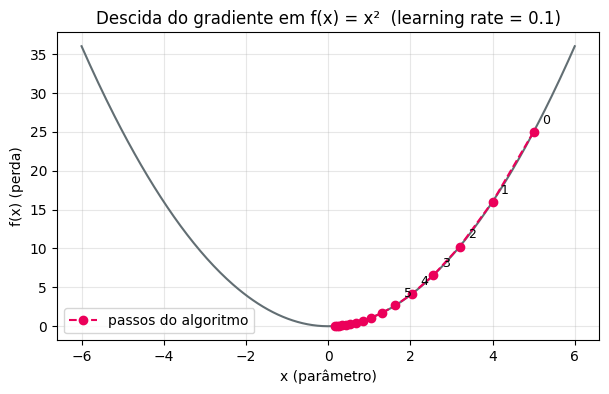

Posição final: 0.1759 | perda final: 0.030949


In [ ]:
def f(x):  return x**2
def grad(x): return 2*x          # derivada de x²: a "inclinação" em cada ponto

def descida_do_gradiente(x0, lr, passos=15):
    hist = [x0]
    x = x0
    for _ in range(passos):
        x = x - lr * grad(x)      # anda na direção OPOSTA ao gradiente
        hist.append(x)
    return np.array(hist)

xs = np.linspace(-6, 6, 300)
h = descida_do_gradiente(x0=5.0, lr=0.1)

plt.figure(figsize=(7,4))
plt.plot(xs, f(xs), color="#626E73")
plt.plot(h, f(h), "o--", color="#EB005A", label="passos do algoritmo")
for i, x in enumerate(h[:6]):
    plt.annotate(str(i), (x, f(x)), textcoords="offset points", xytext=(6,6), fontsize=9)
plt.title("Descida do gradiente em f(x) = x²  (learning rate = 0.1)")
plt.xlabel("x (parâmetro)"); plt.ylabel("f(x) (perda)"); plt.legend(); plt.grid(alpha=.3); plt.show()

print("Posição final:", round(h[-1], 4), "| perda final:", round(f(h[-1]), 6))

Repare: os passos começam grandes (a inclinação é forte longe do mínimo) e vão encolhendo sozinhos perto do vale. Ninguém programou isso: é consequência do gradiente ficar menor perto do mínimo.

## 2. Learning rate: o tamanho do passo muda tudo

Mesma função, mesmo ponto de partida. Só mudamos o tamanho do passo.

NameError: name 'x_train' is not defined

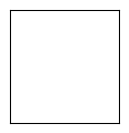

In [13]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

fig = plt.figure(figsize=(20,5))
for i in range(36):
    ax = fig.add_subplot(3, 12, i + 1, xticks=[], yticks=[])
    ax.imshow(np.squeeze(x_train[i]))

**Leitura de negócio.** Quando um time diz "o treino não converge" ou "a perda virou NaN", muitas vezes é isso: passo grande demais.
Quando diz "está treinando há dias e não melhora", pode ser passo pequeno demais. O learning rate é o hiperparâmetro mais importante de qualquer rede.

## 3. Função de ativação: por que a rede precisa ser não linear

Um neurônio faz uma conta simples: soma ponderada das entradas + um viés. Isso é uma reta (ou um plano).
Empilhar dez camadas de retas continua sendo uma reta. Vamos provar com matrizes:

In [ ]:
W1 = np.random.randn(3, 3); W2 = np.random.randn(3, 3); W3 = np.random.randn(3, 3)
x  = np.random.randn(3)

saida_em_3_camadas_lineares = W3 @ (W2 @ (W1 @ x))
W_equivalente = W3 @ W2 @ W1              # uma única matriz faz o mesmo
print("3 camadas lineares:", saida_em_3_camadas_lineares.round(4))
print("1 camada equivalente:", (W_equivalente @ x).round(4))
print("Iguais?", np.allclose(saida_em_3_camadas_lineares, W_equivalente @ x))

3 camadas lineares: [2.0399 1.0405 0.8918]
1 camada equivalente: [2.0399 1.0405 0.8918]
Iguais? True


Iguais. Sem não linearidade, profundidade não serve para nada.
A **função de ativação** é a "dobra" aplicada depois de cada soma. Com dobras, a rede consegue desenhar fronteiras curvas.

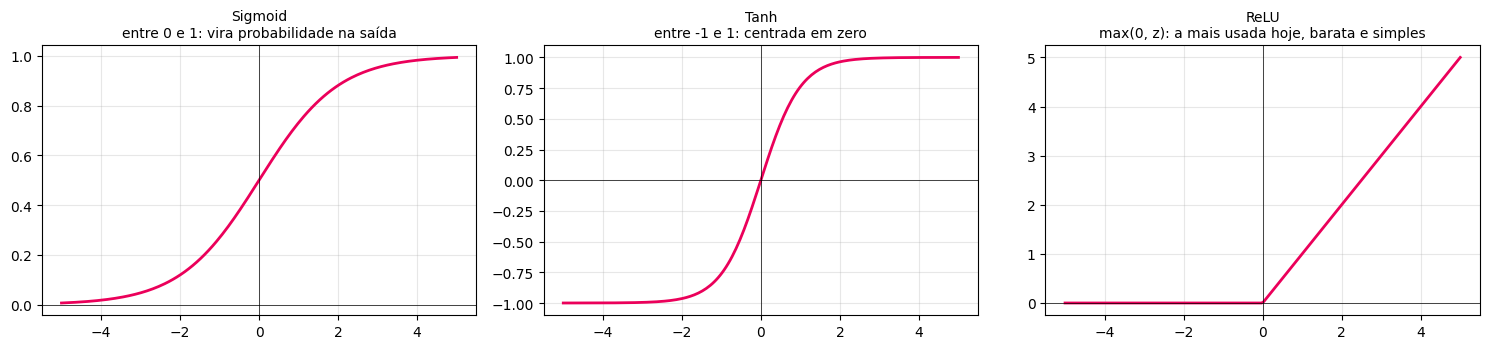

In [ ]:
z = np.linspace(-5, 5, 200)
sigmoid = 1 / (1 + np.exp(-z)); tanh = np.tanh(z); relu = np.maximum(0, z)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, y, nome, nota in zip(axes, [sigmoid, tanh, relu],
                             ["Sigmoid", "Tanh", "ReLU"],
                             ["entre 0 e 1: vira probabilidade na saída", "entre -1 e 1: centrada em zero", "max(0, z): a mais usada hoje, barata e simples"]):
    ax.plot(z, y, color="#EB005A", lw=2); ax.set_title(f"{nome}\n{nota}", fontsize=10); ax.grid(alpha=.3); ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

## 4. Um problema que uma reta não resolve

Dois grupos de clientes em forma de "luas". Uma reta separa os dois? Vamos ver um modelo linear (regressão logística) tentar.

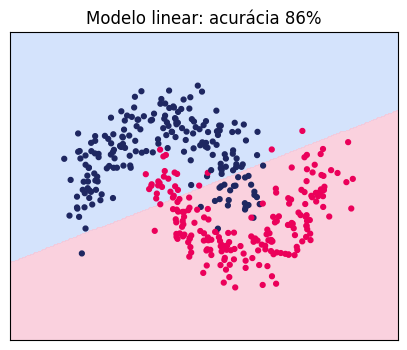

In [ ]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

X, y = make_moons(n_samples=400, noise=0.2, random_state=7)
X = X.astype(np.float32); y = y.astype(np.float32)

def plota_fronteira(predict_fn, X, y, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = np.c_[xx.ravel(), yy.ravel()].astype(np.float32)
    zz = predict_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[0, .5, 1], colors=["#CADCFC", "#F9C6D6"], alpha=.8)
    ax.scatter(X[:,0], X[:,1], c=np.where(y==1, "#EB005A", "#1E2761"), s=12)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])

linear = LogisticRegression().fit(X, y)
fig, ax = plt.subplots(figsize=(5,4))
plota_fronteira(lambda g: linear.predict(g), X, y, ax, f"Modelo linear: acurácia {linear.score(X, y):.0%}")
plt.show()

## 5. Backpropagation visível: de quem é a culpa pelo erro?

Agora uma rede minúscula: 2 entradas, 3 neurônios escondidos, 1 saída. Vamos fazer **uma** previsão, medir o erro e perguntar à rede: *quanto cada peso contribuiu para esse erro?*

Essa pergunta é o backpropagation. A resposta é o gradiente de cada peso. O PyTorch calcula tudo com `loss.backward()`.

In [ ]:

# =====================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# =====================================================

# Importa o PyTorch, utilizado para trabalhar com
# tensores, operações matemáticas e redes neurais.
import torch

# Importa o módulo nn (Neural Network).
# Ele oferece camadas, funções de ativação
# e funções de perda para redes neurais.
from torch import nn


# =====================================================
# 2. CRIAÇÃO DA PRIMEIRA REDE NEURAL
# =====================================================

# nn.Sequential organiza as camadas da rede.
# A saída de uma camada é enviada para a próxima.

modelo = nn.Sequential(

    # Primeira camada:
    # Recebe 2 características de entrada.
    # Possui 3 neurônios na camada oculta.
    # Cada neurônio possui pesos e bias.
    nn.Linear(2, 3),

    # Função de ativação ReLU.
    # Se o valor for negativo, retorna zero.
    # Se for positivo, mantém o valor.
    # Permite aprender relações não lineares.
    nn.ReLU(),

    # Segunda camada:
    # Recebe os 3 valores da camada oculta.
    # Produz apenas 1 valor de saída.
    nn.Linear(3, 1),

    # Função Sigmoid:
    # Transforma a saída em um número entre 0 e 1.
    # Esse valor pode representar a probabilidade
    # da classe positiva em classificação binária.
    nn.Sigmoid()
)


# =====================================================
# 3. DEFINIÇÃO DA FUNÇÃO DE PERDA
# =====================================================

# BCELoss significa Binary Cross Entropy Loss.
# Mede o erro entre a previsão da rede
# e a classe verdadeira (0 ou 1).

perda = nn.BCELoss()


# =====================================================
# 4. CONFIGURAÇÃO DO OTIMIZADOR
# =====================================================

# Adam é um algoritmo utilizado para ajustar
# os pesos e biases durante o treinamento.
#
# modelo.parameters() fornece os parâmetros
# treináveis da rede chamada "modelo".
#
# lr = 0.01 representa a taxa de aprendizagem.

otimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=0.01
)




In [ ]:
# =====================================================
# 5. CRIAÇÃO DE UMA SEGUNDA REDE NEURAL
# =====================================================

# ATENÇÃO:
# Aqui você cria OUTRA rede chamada "rede".
# Ela possui a mesma arquitetura da primeira,
# mas seus pesos são inicializados separadamente.
#
# O otimizador anterior pertence a "modelo",
# e não a esta segunda rede.

rede = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
    nn.Sigmoid()
)


# =====================================================
# 6. FUNÇÃO DE PERDA DA SEGUNDA REDE
# =====================================================

# Define novamente a Binary Cross Entropy.
# Será utilizada para calcular o erro da rede.

perda_fn = nn.BCELoss()


# =====================================================
# 7. SELEÇÃO DE UM EXEMPLO
# =====================================================

# X[:1] seleciona apenas o primeiro registro
# do conjunto de dados X.
#
# torch.tensor converte os dados em um tensor.
#
# A entrada deve conter 2 características,
# porque a primeira camada é nn.Linear(2, 3).
#
# dtype=float32 garante compatibilidade com
# os pesos padrão das camadas PyTorch.

x1 = torch.tensor(
    X[:1],
    dtype=torch.float32
)

# y[:1] seleciona a primeira resposta verdadeira.
#
# unsqueeze(1) adiciona uma dimensão ao tensor.
#
# Exemplo:
# Antes: [1]       formato (1,)
# Depois: [[1]]    formato (1, 1)
#
# Isso permite comparar y1 com a saída da rede.

y1 = torch.tensor(
    y[:1],
    dtype=torch.float32
).unsqueeze(1)


# =====================================================
# 8. FORWARD PROPAGATION
# =====================================================

# Os dados passam pelas camadas da rede:
#
# Entrada -> Linear -> ReLU -> Linear -> Sigmoid
#
# A rede produz uma previsão entre 0 e 1.
#
# IMPORTANTE:
# Os pesos ainda não foram treinados.

previsao = rede(x1)


# =====================================================
# 9. CÁLCULO DO ERRO
# =====================================================

# Compara a previsão com a resposta verdadeira.
#
# Exemplo:
# Previsão = 0.30
# Classe verdadeira = 1
#
# A BCELoss calcula uma penalização para o erro.

perda = perda_fn(previsao, y1)


# =====================================================
# 10. BACKPROPAGATION
# =====================================================

# Calcula os gradientes da perda em relação
# aos pesos e biases da rede.
#
# Esses gradientes indicam como a perda varia
# quando cada parâmetro sofre uma pequena alteração.
#
# IMPORTANTE:
# backward() NÃO atualiza os pesos.
# Apenas calcula os gradientes.

perda.backward()


# =====================================================
# 11. EXIBIÇÃO DA ENTRADA E CLASSE VERDADEIRA
# =====================================================

# x1.numpy() converte o tensor para NumPy.
# round(2) arredonda para 2 casas decimais.
#
# y1.item() extrai o valor numérico do tensor.

print(
    f"Exemplo: x = {x1.numpy().round(2)}, "
    f"classe verdadeira = {int(y1.item())}"
)


# =====================================================
# 12. EXIBIÇÃO DA PREVISÃO E DA PERDA
# =====================================================

# previsao.item() retorna a probabilidade prevista.
# perda.item() retorna o valor numérico do erro.
#
# :.3f apresenta o resultado com 3 casas decimais.

print(
    f"Palpite da rede: {previsao.item():.3f} "
    f"| perda: {perda.item():.3f}\n"
)


# =====================================================
# 13. VISUALIZAÇÃO DOS GRADIENTES
# =====================================================

print("Gradiente ('culpa') de cada parâmetro:")

# named_parameters() percorre todos os parâmetros
# treináveis da rede, incluindo pesos e biases.

for nome, p in rede.named_parameters():

    # nome identifica o parâmetro:
    #
    # 0.weight = pesos da primeira camada
    # 0.bias   = biases da primeira camada
    # 2.weight = pesos da segunda camada
    # 2.bias   = bias da segunda camada
    #
    # detach() permite inspecionar os valores
    # sem manter a ligação com o grafo de gradientes.
    #
    # round(2) arredonda os números.
    # tolist() converte os valores para listas Python.

    print(
        f"  {nome:<10} "
        f"valores={p.detach().numpy().round(2).tolist()}"
    )

    # p.grad contém os gradientes calculados
    # durante o backward().
    #
    # Gradiente positivo:
    # aumentar ligeiramente o parâmetro tende
    # a aumentar a perda.
    #
    # Gradiente negativo:
    # aumentar ligeiramente o parâmetro tende
    # a diminuir a perda.
    #
    # Gradiente próximo de zero:
    # pequena sensibilidade local da perda
    # à alteração desse parâmetro.

    print(
        f"  {'':<10} "
        f"grad={p.grad.detach().numpy().round(3).tolist()}"
    )


Exemplo: x = [[ 0.55 -0.33]], classe verdadeira = 1
Palpite da rede: 0.371 | perda: 0.993

Gradiente ('culpa') de cada parâmetro:
  0.weight   valores=[[-0.3499999940395355, -0.5400000214576721], [-0.5299999713897705, 0.11999999731779099], [-0.6899999976158142, 0.09000000357627869]]
             grad=[[0.0, -0.0], [0.0, -0.0], [0.0, -0.0]]
  0.bias     valores=[-0.6299999952316284, -0.23999999463558197, -0.6000000238418579]
             grad=[0.0, 0.0, 0.0]
  2.weight   valores=[[-0.3100000023841858, 0.23000000417232513, -0.3100000023841858]]
             grad=[[0.0, 0.0, 0.0]]
  2.bias     valores=[-0.5299999713897705]
             grad=[-0.6290000081062317]


Peso com gradiente grande = teve muita influência no erro. Peso com gradiente zero = não participou (repare nos neurônios "desligados" pela ReLU).

Agora o passo de aprendizado, à mão: `peso = peso - lr * gradiente`. Depois, medimos o erro de novo no mesmo exemplo.

In [ ]:
lr = 0.5
with torch.no_grad():
    for p in rede.parameters():
        p -= lr * p.grad            # o passo da descida do gradiente, peso a peso
    nova_perda = perda_fn(rede(x1), y1)

print(f"Perda antes do passo: {perda.item():.4f}")
print(f"Perda depois do passo: {nova_perda.item():.4f}")
print("Diminuiu?", nova_perda.item() < perda.item())

Perda antes do passo: 0.9928
Perda depois do passo: 0.8065
Diminuiu? True


Isso é tudo que uma rede neural faz, milhões de vezes: palpite, erro, culpa, passo. Treinar é repetir esse ciclo sobre muitos exemplos (épocas).

## 6. A rede aprendendo ao vivo

Agora a rede completa treina sobre os 400 pontos. Tiramos "fotos" da fronteira de decisão em algumas épocas.

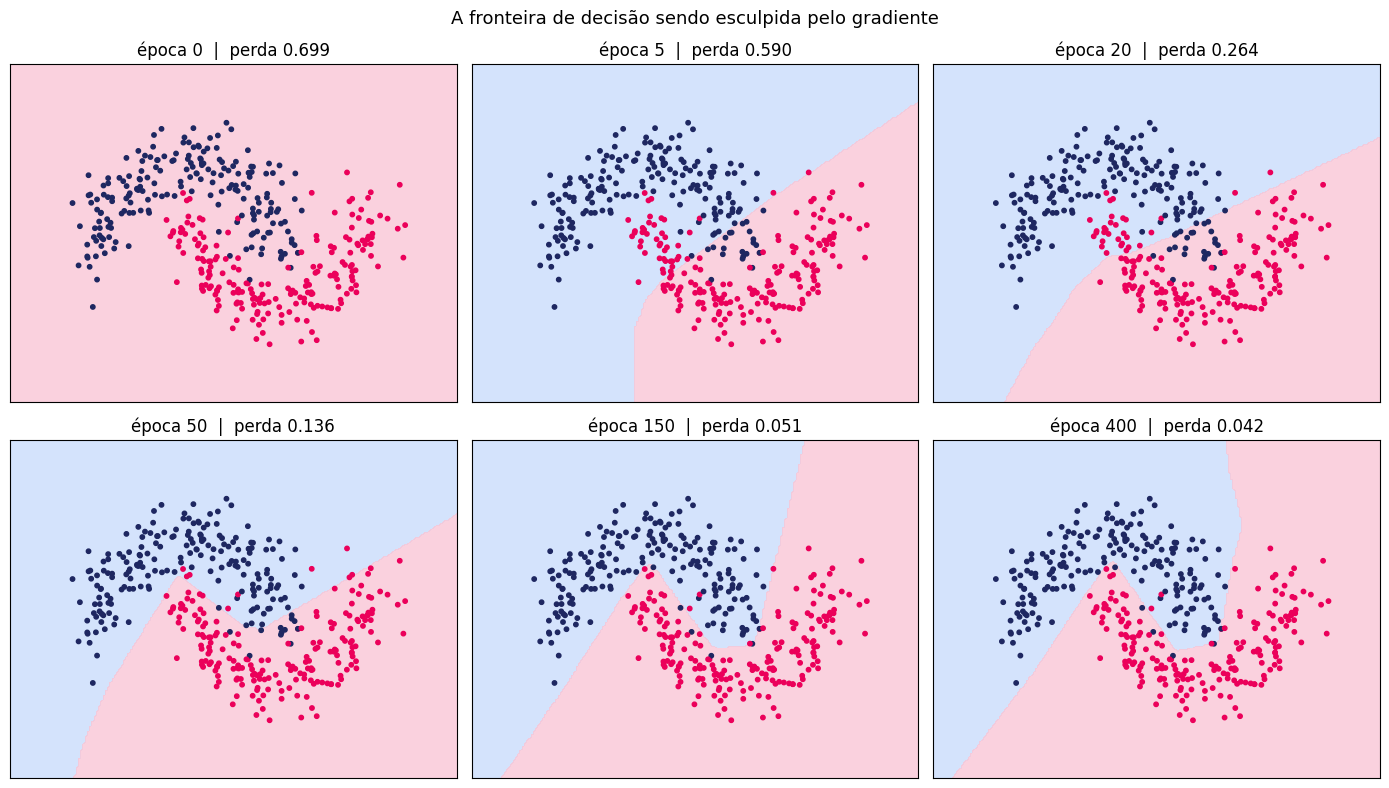

Acurácia final da rede: 98%  (o modelo linear tinha 86%)


In [ ]:
torch.manual_seed(0)
rede = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
otimizador = torch.optim.Adam(rede.parameters(), lr=0.02)
Xt, yt = torch.tensor(X), torch.tensor(y).unsqueeze(1)

fotos = {0, 5, 20, 50, 150, 400}
snapshots, perdas = {}, []
predict = lambda g: (rede(torch.tensor(g)).detach().numpy() > 0.5).astype(int)

for epoca in range(401):
    if epoca in fotos:
        xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
        snapshots[epoca] = predict(np.c_[xx.ravel(), yy.ravel()].astype(np.float32)).reshape(xx.shape)
    otimizador.zero_grad()
    perda = perda_fn(rede(Xt), yt)      # palpite + erro (em todos os pontos)
    perda.backward()                    # culpa
    otimizador.step()                   # passo
    perdas.append(perda.item())

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (ep, zz) in zip(axes.ravel(), sorted(snapshots.items())):
    ax.contourf(xx, yy, zz, levels=[-.5, .5, 1.5], colors=["#CADCFC", "#F9C6D6"], alpha=.8)
    ax.scatter(X[:,0], X[:,1], c=np.where(y==1, "#EB005A", "#1E2761"), s=10)
    ax.set_title(f"época {ep}  |  perda {perdas[min(ep, len(perdas)-1)]:.3f}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("A fronteira de decisão sendo esculpida pelo gradiente", fontsize=13); plt.tight_layout(); plt.show()

acc = ((rede(Xt) > 0.5).float() == yt).float().mean().item()
print(f"Acurácia final da rede: {acc:.0%}  (o modelo linear tinha {linear.score(X, y):.0%})")

In [ ]:
plt.figure(figsize=(7,3.5))
plt.plot(perdas, color="#EB005A"); plt.xlabel("época"); plt.ylabel("perda (erro)"); plt.title("Curva de aprendizado"); plt.grid(alpha=.3); plt.show()

## O que levar desta demo

| Conceito | Em uma frase |
|---|---|
| Função de perda | O número que diz quanto o modelo errou. |
| Gradiente | A direção em que o erro cresce mais rápido. Andamos no sentido contrário. |
| Learning rate | Tamanho do passo. Grande demais explode, pequeno demais demora. |
| Função de ativação | A "dobra" que permite fronteiras curvas. Sem ela, profundidade é inútil. |
| Backpropagation | O cálculo da culpa de cada peso pelo erro, da saída para a entrada. |
| Época | Uma passada completa pelos dados de treino. |

**Próximo notebook:** a mesma mecânica, agora sobre imagens: uma rede convolucional classificando 10 tipos de objeto.